# Excavator arm kinematics with a constraint sketch

The example is the arm of a 20 t excavator, a planar mechanism: boom, stick and bucket, a four-bar linkage that turns
the bucket, and three hydraulic cylinders. In a constraint sketch, it is drawn once from the pin table of the drawing
and dimensioned. The three cylinder lengths are its only free dimensions, and the solver does the kinematics,
including the closed loop of the bucket linkage. There are no loop equations, no trigonometry, and no assembly
branches to pick by hand. The same sketch also answers the inverse question: which cylinder lengths put the tooth where
the operator wants it.

![An excavator arm grading a level trench floor, its three cylinders found by the sketch](../_static/gallery/excavator-arm.gif){.result}

In [1]:
import math
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import planex as px

## The pin table

The pins are given in meters, with the arm in the pose of the drawing and the origin on the ground at the swing
axis.

| Pin | On | Role |
|---|---|---|
| O | Frame, boom | Boom foot |
| A | Frame | Boom cylinder base |
| B | Boom | Boom cylinder eye |
| K | Boom | Stick cylinder base |
| C | Boom, stick | Stick pivot |
| E | Stick | Stick cylinder eye |
| F | Stick | Bucket cylinder base |
| G | Stick, rocker | Rocker pivot |
| H | Stick, bucket | Bucket pivot |
| R | Rocker, link | Bucket cylinder eye |
| J | Link, bucket | Link pin |
| T | Bucket | Tooth tip |

Each body lists its main pin first and the pin that sets its direction second. The strokes are the closed and the
open length of each cylinder.

In [2]:
pins = {
    "O": (0.200, 2.000), "A": (0.300, 0.900),
    "B": (2.325, 3.920), "K": (2.025, 4.439), "C": (5.136, 4.850),
    "E": (5.461, 5.713), "F": (5.790, 4.662), "G": (6.085, 2.535), "H": (6.128, 2.125),
    "R": (6.724, 2.655), "J": (6.578, 2.125), "T": (6.624, 0.762),
}
frame = "OA"
bodies = {"boom": "OCBK", "stick": "CHEFG", "bucket": "HJT", "rocker": "GR", "link": "RJ"}
cylinders = {"boom": "AB", "stick": "KE", "bucket": "FR"}
strokes = {"boom": (2.40, 3.90), "stick": (2.65, 4.00), "bucket": (1.85, 2.75)}

## The sketch

Every line runs from pin to pin and takes its id and its name from them (`"OC"`, `"AB"`). The constraints refer to it
by its id, and its name finds it again among the solved edges. A pin that is already drawn is shared
(`Move(..., px.Coincident)`), and the two frame pins are fixed.

A body is rigid when every pin keeps its distance from the main pin and its angle to the body's direction, which is
one length and one angle per pin. (Lengths alone would also work, but on a long, slender stick the triangles get so
flat that the mirror image of a pin is only centimeters away.) Each cylinder gets a length with an id, and these are
the dimensions that move the arm.

In [3]:
sk = px.Sketch()
point = {}


def line(a, b):
    if a in point:
        sk.Move(point[a], px.Coincident)
    elif a in frame:
        sk.Move(pins[a], px.Fix)
    else:
        sk.Move(tuple(pins[a]))
    sk.Line(pins[b], id=a + b, name=a + b)
    if b in point:
        sk.Constrain(a + b + ".end", point[b], px.Coincident)
    point.setdefault(a, a + b + ".start")
    point.setdefault(b, a + b + ".end")
    return a + b


def turn(hub, ref, p):
    (hx, hy), (rx, ry), (x, y) = pins[hub], pins[ref], pins[p]
    return math.degrees(math.atan2(y - hy, x - hx) - math.atan2(ry - hy, rx - hx))


for hub, ref, *others in bodies.values():
    sk.Constrain(line(hub, ref), px.Distance, math.dist(pins[hub], pins[ref]))
    for p in others:
        sk.Constrain(line(hub, p), px.Distance, math.dist(pins[hub], pins[p]))
        sk.Constrain(hub + ref, hub + p, px.Angle, turn(hub, ref, p))
for name, (a, b) in cylinders.items():
    sk.Constrain(line(a, b), px.Distance, math.dist(pins[a], pins[b]), id=name)
print(sk)

Sketch(45 elements, 38 constraints, full, 0 degrees of freedom)


The sketch is fully constrained and green everywhere. Hovering over a line shows its id.

<Axes: >

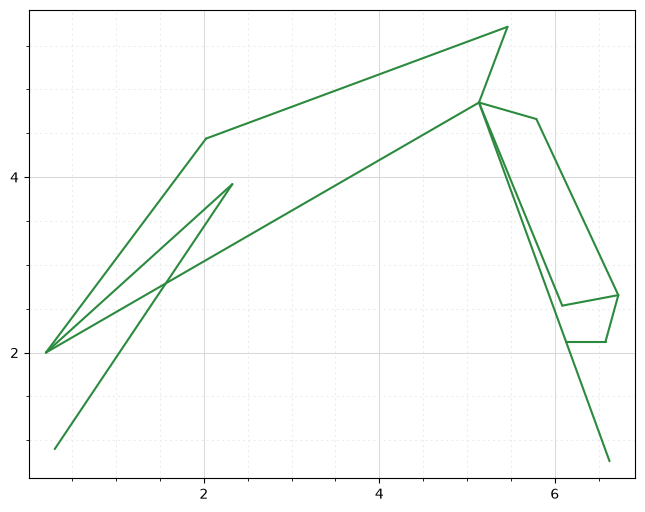

In [4]:
sk.Plot()

## Moving the arm

`Update` sets new cylinder lengths and solves. The pins are read back from the solved lines: each line starts at its
first pin and ends at its second.

In [5]:
def solved():
    out = {}
    for wire in sk.Wires(unify=False):
        for e in wire.edges:
            out[e.name[0]] = (e.start.h, e.start.v)
            out[e.name[1]] = (e.end.h, e.end.v)
    return out


sk.Update({"boom": 3.2, "stick": 3.3, "bucket": 2.3})
p = solved()

**Checks:**

- the boom turns about the boom foot O, and the triangle O, A, B has three known sides, so the law of cosines gives
  where the boom cylinder eye B must be;
- every body still has the shape of the drawing.

In [6]:
O, A = np.array(pins["O"]), np.array(pins["A"])
OA, OB = math.dist(pins["O"], pins["A"]), math.dist(pins["O"], pins["B"])
at_O = math.acos((OA**2 + OB**2 - sk["boom"] ** 2) / (2 * OA * OB))
to_A = math.atan2(*(A - O)[::-1])
B = O + OB * np.array([math.cos(to_A + at_O), math.sin(to_A + at_O)])
print("B solved", p["B"], "law of cosines", B.tolist(), "difference", np.linalg.norm(p["B"] - B))

shape = max(abs(math.dist(p[a], p[b]) - math.dist(pins[a], pins[b]))
            for names in bodies.values() for a in names for b in names)
print("largest change of a distance inside a body", shape, "m")

B solved (2.9946935271514326, 2.625869866104677) law of cosines [2.994693527151433, 2.6258698661046753] difference 1.831026719408895e-15
largest change of a distance inside a body 1.3322676295501878e-15 m


## Drawing the bodies

For the pictures, every body gets a plate: the polygon through its pins grown with `Offset` (with rounded corners),
and a bore at every pin. The boom's polygon has one point of its own at its bend, and the bucket is drawn with a
spline for its back.

In [7]:
def bores(names, r):
    return [px.QuickSketch().Circle(*pins[n], r).Face() for n in names]


def plate(names, grow, bore, outline=None):
    pts = outline or [pins[n] for n in names]
    if len(pts) == 2:
        body = px.Line(*pts).Offset(grow)
    else:
        poly = px.FromPolyline(pts, closed=True).Face()
        body = px.Unify([poly, poly.outer.Offset(grow)])
    return px.Subtract([body, *bores(names, bore)])


shell = px.QuickSketch(pins["H"]).Line(pins["J"]).Spline([(7.08, 1.83), (7.15, 1.28), (6.95, 0.86), pins["T"]])
shell = shell.Close().Face()
plates = {
    "boom": plate("OBCK", 0.16, 0.055, outline=[pins["O"], (2.45, 3.66), pins["C"], pins["K"]]),
    "stick": plate("EFGHC", 0.12, 0.05),
    "bucket": px.Subtract([px.Unify([shell, shell.outer.Offset(0.03)]), *bores("HJ", 0.045)]),
    "rocker": plate("GR", 0.07, 0.04),
    "link": plate("RJ", 0.07, 0.04),
}

Each plate is made once, in the pose of the drawing, and then moved along with its body by `Rotated` and
`Translated`. The cylinders are drawn as a barrel and a rod between their pins.

In [8]:
def placed(name, p):
    hub, ref = bodies[name][:2]
    (hx, hy), (rx, ry) = pins[hub], pins[ref]
    (qx, qy), (sx, sy) = p[hub], p[ref]
    turn = math.degrees(math.atan2(sy - qy, sx - qx) - math.atan2(ry - hy, rx - hx))
    return plates[name].Rotated(pins[hub], turn).Translated((qx - hx, qy - hy))


def cylinder(name, p):
    a, b = (np.array(p[k]) for k in cylinders[name])
    u = (b - a) / np.linalg.norm(b - a)
    barrel = px.Line(tuple(a), tuple(a + (strokes[name][0] - 0.2) * u)).Offset(0.085)
    rod = px.Line(tuple(a), tuple(b)).Offset(0.04)
    return rod, barrel

The arm in the pose of the drawing, with its pins:

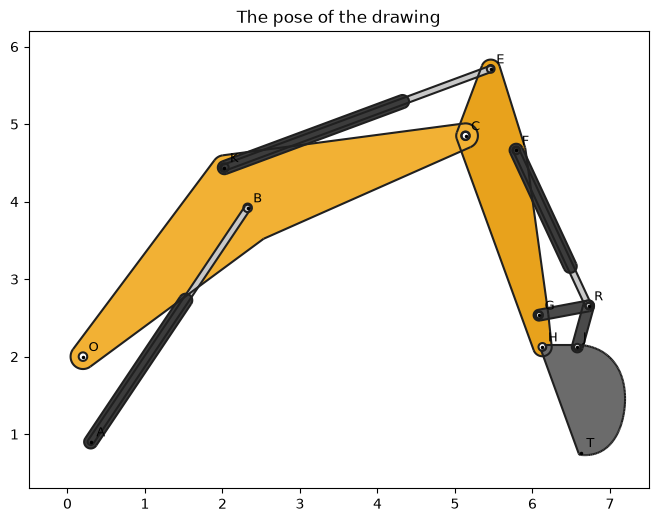

In [9]:
colors = {"boom": "#f2b134", "stick": "#e8a21c", "bucket": "#6b6b6b", "rocker": "#4a4a4a", "link": "#4a4a4a"}


def draw(ax, p, alpha=1.0):
    def fill(face, col):
        rgb = plt.matplotlib.colors.to_rgb(col)
        px.Plot(face, ax=ax, face_col=(*rgb, alpha), line_col="#202020", arc_col="#202020", spline_col="#202020",
                legend=False)
    for name in ("stick", "bucket", "rocker", "link", "bucket cylinder", "boom", "stick cylinder", "boom cylinder"):
        if name.endswith("cylinder"):
            rod, barrel = cylinder(name.split()[0], p)
            fill(rod, "#c8c8c8")
            fill(barrel, "#3c3c3c")
        else:
            fill(placed(name, p), colors[name])


fig, ax = plt.subplots(figsize=(8, 6))
ax.set_xlim(-0.5, 7.5)
ax.set_ylim(0.3, 6.2)
draw(ax, pins)
ax.plot(*zip(*pins.values()), ".", color="k", ms=3)
for name, xy in pins.items():
    ax.annotate(name, xy, xytext=(4, 4), textcoords="offset points", fontsize=9)
ax.set_title("The pose of the drawing")
plt.show()

## Working range

The data sheet of an excavator shows where the tooth tip can go. Here, the three cylinder lengths run through their
strokes on a grid, back and forth, so that every solve starts next to the previous one, and each solve takes a
fraction of a millisecond. Each cell of the grid, in each of its three directions, gives two small triangles of tip
positions, and their union is the working range as one planex2d face.

The grid has 21 lengths of the boom cylinder, 21 of the stick cylinder and 15 of the bucket cylinder:

In [10]:
lengths = {name: np.linspace(*strokes[name], n) for name, n in zip(cylinders, (21, 21, 15))}
tips = np.zeros((15, 21, 21, 2))
start = time.perf_counter()
solves = 0
for k in range(15):
    for i in range(21) if k % 2 == 0 else reversed(range(21)):
        for j in range(21) if (i + k) % 2 == 0 else reversed(range(21)):
            sk.Update({"boom": lengths["boom"][i], "stick": lengths["stick"][j], "bucket": lengths["bucket"][k]})
            tips[k, i, j] = solved()["T"]
            solves += 1
print(solves, "positions in", round(time.perf_counter() - start, 1), "s")

6615 positions in 2.6 s


In [11]:
def cells(grid):
    for row in grid:
        for i in range(row.shape[0] - 1):
            for j in range(row.shape[1] - 1):
                yield (tuple(row[i + di, j + dj]) for di, dj in ((0, 0), (1, 0), (1, 1), (0, 1)))


start = time.perf_counter()
triangles = []
for grid in (tips, tips.transpose(1, 0, 2, 3), tips.transpose(2, 0, 1, 3)):
    for a, b, c, d in cells(grid):
        triangles += [px.FromPolyline([a, b, c], closed=True).Face(), px.FromPolyline([a, c, d], closed=True).Face()]
reach = px.Unify(triangles).faces[0]
print("union of", len(triangles), "triangles in", round(time.perf_counter() - start, 1), "s:",
      len(reach.outer.edges), "edges, area", round(reach.mass, 2), "m²")

union of 35520 triangles in 0.7 s: 144 edges, area 88.99 m²


The numbers of the data sheet are read off the face: the reach at ground level where the ground line leaves it, and
the digging depth and cutting height from its bounding box.

In [12]:
ground = px.Line((0, 0), (15, 0))
at_ground = max(q.x for q in reach.outer.Intersections(ground))
(xmin, ymin), (xmax, ymax) = reach.bounding_box
print("reach at ground level", round(at_ground, 2), "m")
print("digging depth", round(-ymin, 2), "m")
print("cutting height", round(ymax, 2), "m")

reach at ground level 9.73 m
digging depth 6.18 m
cutting height 9.59 m


The working range with the arm in three poses: digging, at ground level and high.

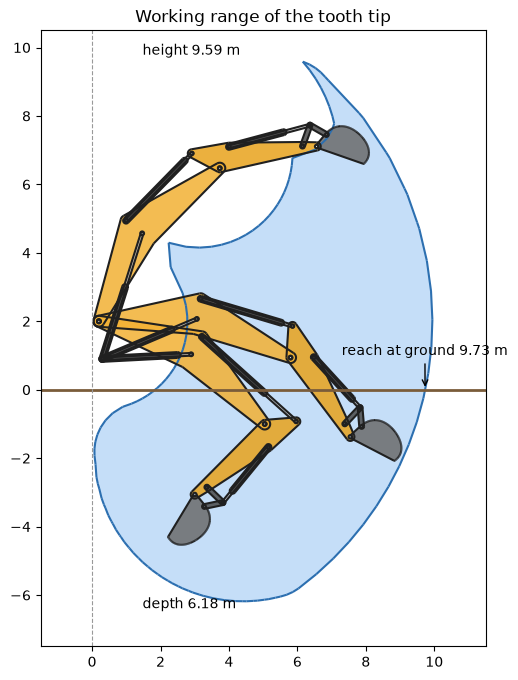

In [13]:
poses = {"digging": (2.6, 3.7, 2.1), "at ground": (3.0, 2.8, 2.0), "high": (3.85, 2.75, 2.45)}
envelope, ax = plt.subplots(figsize=(9, 8))
ax.set_xlim(-1.5, 11.5)
ax.set_ylim(-7.5, 10.5)
px.Plot(reach, ax=ax, face_col=(0.55, 0.75, 0.95, 0.5), line_col="#2c6fb0", arc_col="#2c6fb0", spline_col="#2c6fb0",
        legend=False)
for name, (lb, ls, lk) in poses.items():
    sk.Update({"boom": lb, "stick": ls, "bucket": lk})
    draw(ax, solved(), alpha=0.85)
ax.axhline(0, color="#7a5c3a", lw=2)
ax.axvline(0, color="#999999", lw=0.8, ls="--")
ax.annotate(f"reach at ground {at_ground:.2f} m", (at_ground, 0), xytext=(-60, 25), textcoords="offset points",
            arrowprops={"arrowstyle": "->"})
ax.annotate(f"depth {-ymin:.2f} m", (xmin + 1, ymin), xytext=(10, -5), textcoords="offset points")
ax.annotate(f"height {ymax:.2f} m", (xmin + 1, ymax), xytext=(10, 5), textcoords="offset points")
ax.set_title("Working range of the tooth tip")
plt.show()

## Inverse kinematics: grading a trench floor

The operator wants the tooth to run along a level floor 1.5 m deep, with the bucket held at a constant angle (the
line from the bucket pivot to the tooth at −100°). In the sketch, that is just another set of dimensions. Starting from
a pose near the floor, the three cylinder lengths are removed and replaced by the tooth's depth, its distance from the
swing axis and the angle of the bucket, measured in the current pose and then set to the required values. The sketch
is again fully constrained, and the cylinder lengths are now read off the solved lines (the `mass` of a line is its
length).

In [14]:
sk.Update({"boom": 3.3, "stick": 3.55, "bucket": 2.35})
p = solved()
for name in cylinders:
    sk.Remove(name)
print(sk)
sk.Constrain(point["T"], px.H, px.Distance, -p["T"][1], id="depth")
sk.Constrain(point["T"], px.V, px.Distance, p["T"][0], id="x")
attack = math.degrees(math.atan2(p["T"][1] - p["H"][1], p["T"][0] - p["H"][0]))
sk.Constrain(px.H, "HT", px.Angle, attack, id="attack")
sk.Update({"depth": 1.5, "x": 6.0, "attack": -100})
print(sk)
print("tooth at", solved()["T"])

Sketch(45 elements, 35 constraints, under, 3 degrees of freedom)
Sketch(45 elements, 38 constraints, full, 0 degrees of freedom)
tooth at (6.0, -1.4999999999999996)


The tooth moves along the floor from 6 m out to 8 m, and from 6 m in to 3 m, and every position is one `Update`.
Where all three lengths lie within their strokes, the floor can actually be graded. (A target that the arm cannot reach
makes `Update` raise an error and leaves the sketch as it was.)

In [15]:
def cylinder_lengths():
    return {name: e.mass for wire in sk.Wires(unify=False) for e in wire.edges
            for name, ab in cylinders.items() if e.name == ab}


def follow(xs):
    track = []
    for x in xs:
        sk.Update({"x": x})
        track.append((x, cylinder_lengths(), solved()))
    return track


track = follow(np.linspace(6.0, 8.0, 41))[::-1]
sk.Update({"x": 6.0})
track += follow(np.linspace(6.0, 3.0, 61))[1:]
xs = np.array([x for x, _, _ in track])
needed = {name: np.array([lengths[name] for _, lengths, _ in track]) for name in cylinders}
inside = np.all([(strokes[n][0] <= needed[n]) & (needed[n] <= strokes[n][1]) for n in cylinders], axis=0)
print("within the strokes from x =", round(xs[inside].max(), 2), "m to", round(xs[inside].min(), 2), "m")

within the strokes from x = 7.95 m to 3.45 m


The chart shows the three cylinder lengths along the floor, with their strokes as bands:

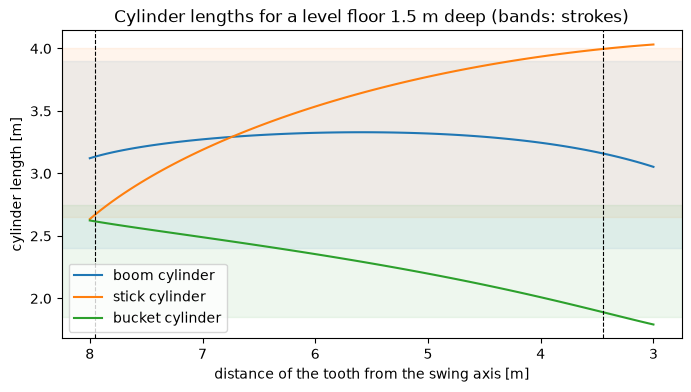

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
for (name, values), col in zip(needed.items(), ("C0", "C1", "C2")):
    ax.plot(xs, values, color=col, label=f"{name} cylinder")
    ax.axhspan(*strokes[name], color=col, alpha=0.08)
for x in (xs[inside].max(), xs[inside].min()):
    ax.axvline(x, color="k", lw=0.8, ls="--")
ax.set_xlabel("distance of the tooth from the swing axis [m]")
ax.set_ylabel("cylinder length [m]")
ax.invert_xaxis()
ax.legend()
ax.set_title("Cylinder lengths for a level floor 1.5 m deep (bands: strokes)")
plt.show()

The arm grading the floor, back and forth within the strokes:

In [17]:
grading = [pose for (x, _, pose), ok in zip(track, inside) if ok][::3]
grading += grading[::-1]

plt.rcParams["animation.frame_format"] = "jpeg"
fig, ax = plt.subplots(figsize=(8, 6))


def frame(k):
    ax.clear()
    ax.set_xlim(-1.5, 11.5)
    ax.set_ylim(-3, 9)
    ax.fill_between([-1.5, 11.5], [0, 0], [-7, -7], color="#c9b18f", alpha=0.5)
    ax.fill_between([xs[inside].min(), xs[inside].max()], [0, 0], [-1.5, -1.5], color="white")
    draw(ax, grading[k])
    ax.plot(*grading[k]["T"], "o", color="crimson", ms=4)
    ax.set_title(f"Tooth at x = {grading[k]['T'][0]:.2f} m, 1.5 m deep")


animation = FuncAnimation(fig, frame, frames=len(grading), interval=60)
plt.close(fig)
HTML(animation.to_jshtml())

The way back also works. The cylinder lengths found for one position become dimensions again, the tooth's dimensions
are removed, and the forward solve puts the tooth where it was.

In [18]:
x = round(float(np.median(xs[inside])), 1)
sk.Update({"x": x})
target, found = solved()["T"], cylinder_lengths()
for name in ("depth", "x", "attack"):
    sk.Remove(name)
for name, (a, b) in cylinders.items():
    sk.Constrain(a + b, px.Distance, found[name], id=name)
print(sk)
print("tooth after the forward solve", solved()["T"], "wanted", (x, -1.5))
print("difference", np.linalg.norm(np.subtract(solved()["T"], target)))

Sketch(45 elements, 38 constraints, full, 0 degrees of freedom)
tooth after the forward solve (5.7, -1.4999999999999996) wanted (5.7, -1.5)
difference 0.0


In [19]:
import sys
sys.path.insert(0, "..")
from gallery import save_scene, save_figure, save_animation, HIDDEN
save_animation(animation, "excavator-arm", still=False, bare=True)
save_figure(envelope, "excavator-arm", bare=True)

'/workspace/planex/documentation/docs/_static/gallery/excavator-arm.png'